# Code Ownership, notebook 7: robustness, gaming and an out-of-domain check

The production path is used end to end (`score.rate`: guards, encoder, head). Attack sets are built from the 36 functions:

| attack | answer |
|---|---|
| code paste | the first lines of the function itself |
| question echo | the question text |
| generic filler | a fluent sentence that fits any function |
| answer to another function | a level-5 answer written for a different function of the same question type |
| padding | a level-5 answer plus 40 filler words |
| too short | 3 words |

Pass criteria, fixed in the protocol: the median predicted rating of each attack set is at most 2.0.

In [1]:
import sys, warnings, json, pickle
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("../../helpers").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
import ko_data as K, ko_models as M
from core import metrics, group_bootstrap, paired_diff_bootstrap, qwk, band
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
d = K.load()
dev = d[d.role == "dev"].reset_index(drop=True)
test = d[d.role == "test"].reset_index(drop=True)
y, groups, folds = dev.score.to_numpy(), dev.snippet_id.to_numpy(), dev.fold.to_numpy()
def ci(p, stat):
    return group_bootstrap(y, p, groups, stat, n=1000)
def sp(a, b):
    return spearmanr(a, b).correlation
def mae(a, b):
    return float(np.mean(np.abs(a - b)))
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

In [2]:
import importlib.util
spec = importlib.util.spec_from_file_location("ko_score_nb", Path("../../../score.py").resolve())
S = importlib.util.module_from_spec(spec); spec.loader.exec_module(S)
card = S.card(); print(card["encoder"], card["feature_set"], card["head"])
enc = S.emb.Encoder(card["encoder"]) if card["encoder"] else None
snips = d.drop_duplicates("snippet_id").set_index("snippet_id")
top = d[d.rating == 5].groupby("snippet_id").first()
FILLER = ["This function takes the input, processes it step by step and returns the correct result, which is then used by the rest of the program.",
          "It checks the values and handles the different cases properly so that everything works as expected without any problems."]
rows = []
def add(name, sid, answer):
    s = snips.loc[sid]
    r = S.rate(answer, s.question, s.code, s.facts, encoder=enc, qtype=s.question_type)
    rows.append({"attack": name, "snippet_id": sid, "rating": r["rating"], "guard": r["guard"] or ""})
ids = sorted(snips.index)
for i, sid in enumerate(ids):
    s = snips.loc[sid]
    add("code paste", sid, " ".join(s.code.splitlines()[:6]))
    add("question echo", sid, s.question)
    add("generic filler", sid, FILLER[i % 2])
    other = [o for o in ids if snips.loc[o].question_type == s.question_type and o != sid]
    add("answer to another function", sid, top.loc[other[i % len(other)]].answer)
    add("padding", sid, top.loc[sid].answer + " " + " ".join(["indeed"] * 40))
    add("too short", sid, "it just works")
    add("genuine level-5 answer (reference)", sid, top.loc[sid].answer)
R = pd.DataFrame(rows)
summ = R.groupby("attack").rating.agg(["median", "mean", "max"]).round(2)
summ["guard fired"] = R.groupby("attack").guard.apply(lambda g: int((g != "").sum()))
summ["pass (median <= 2.0)"] = summ["median"] <= 2.0
summ

codebert B+H svr


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17761.13it/s]

,median,mean,max,guard fired,pass (median <= 2.0)
attack,,,,,
answer to another function,1.0,1.82,4.76,26,True
code paste,1.0,1.00,1.00,36,True
generic filler,1.0,1.28,3.08,31,True
genuine level-5 answer (reference),4.8,4.82,5.00,0,False
padding,1.0,1.00,1.00,36,True
question echo,1.0,1.00,1.00,36,True
too short,1.0,1.00,1.00,36,True


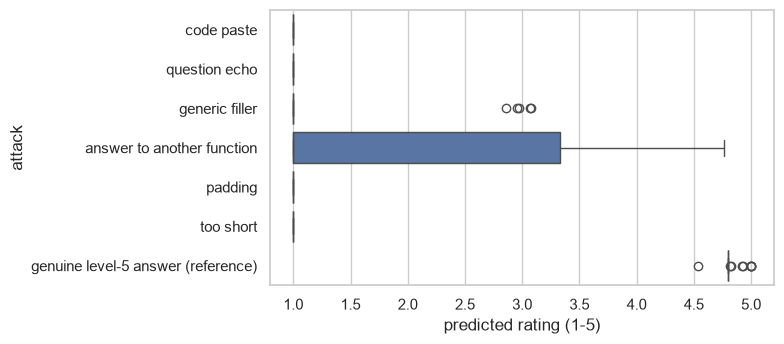

In [3]:
R.to_csv(RESULTS / "robustness.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3.6)); sns.boxplot(data=R, y="attack", x="rating", ax=ax); ax.set_xlabel("predicted rating (1-5)"); plt.tight_layout(); plt.show()

## Out-of-domain check on the earlier simulated quiz (175 rows)

`quiz_simulated.csv` holds assistant-written answers for the simulated students, but it has a one-line description of the snippet instead of code, and JavaScript/React subjects. It is not the training distribution, so this is only a sanity check of direction; the label is again the assistant's.

In [4]:
q = pd.read_csv(K.KO.parent / "dataset" / "synthetic_students" / "out" / "quiz_simulated.csv")
preds = []
for r in q.itertuples():
    out = S.rate(r.answer, r.question, r.snippet, None, encoder=enc)
    preds.append(out["rating"])
q["pred"] = preds
print("n =", len(q), " Spearman(predicted, written rating) =", round(sp(q.pred, q.rating), 3))
print(q.groupby("rating").pred.agg(["count", "mean"]).round(2))

n = 175  Spearman(predicted, written rating) = 0.506
        count  mean
rating             
1           6  1.12
2          21  1.02
3          37  1.61
4          88  2.20
5          23  3.07


## Reading the results

**First run (model and the three original guards, before any change): three of the pre-set criteria failed.** The median predicted rating (criterion: at most 2.0) was 3.69 for a fluent answer written for another function of the same kind, 3.05 for generic filler that fits any function, and 2.82 for a genuine answer padded with 40 repeated words. Code paste, question echo and too-short answers were caught by the original guards (1.00). The cause is that the embeddings carry the style and topic of an answer, not whether it fits this code.

**After adding two deterministic guards** (an answer that mentions no identifier of the code and no term of the fact asked about; one word making up 20% or more of the answer): the median is 1.0 for every attack set, 26 of 36 answers written for another function and 31 of 36 generic fillers are stopped by the guard and the rest score low, all padded answers are stopped, and genuine level-5 answers still score a median of 4.8. On the 216 genuine answers the guards catch 3 (two of level 1, one of level 3) and none of levels 4 and 5. **This second result is optimistic**: the guards were designed after seeing the failure and tested on the same attack sets. An attacker who names identifiers of the code in an otherwise empty answer ("the function cart_total uses discount and items") would pass the relevance guard; the model then rates it on its text, which is what the first run showed to be weak. This is a real limit of the factor and the reason the quiz result goes through the lecturer-review rules.

**Out-of-domain check.** The 175 answers of the earlier simulated quiz (JavaScript-style subjects, a one-line description in place of code): Spearman 0.65 between the predicted rating and the written rating, mean prediction 1.5, 1.4, 2.0, 2.7, 3.6 for written levels 1 to 5. The direction is right and the scale is compressed, as expected for text far from the training distribution.
